# Vertex selection for taus: analysis notebook

Main working notebook. Day 1 goal: **define what we evaluate and what "correct" means, then reproduce the
first-look ΣpT² numbers with my own code.**

Day-1 tasks (each with a check):
1. **Tau selection**: truth hadronic taus from the γ*, visible pT > 20 GeV, |η| < 2.5, matched to a reco jet
   (ΔR < 0.2, jet pT > 20 GeV). *Check*: counts per μ; matched fraction ≈ 0.97 at μ = 0 falling with μ (fig 7).
2. **Truth label**: which reco candidate vertex is the correct interaction vertex (majority-of-HS-tracks rule,
   purity > 50%). *Check*: ceiling ≈ 0.997 at μ = 0, ≈ 0.85 at μ = 200.
3. **ΣpT²**: per event, Σ pT² of each candidate's tracks, pick the max. *Check*: my Σ pT² equals Delphes'
   `rv_sumpt2`; efficiency reproduces 0.987 / … / 0.649 (event-level).
4. **Efficiency**: per tau, with Wilson errors, vs μ.

Rules: `truth_*` columns only **select** which taus are evaluated and **define labels**, never feed an
algorithm (`samples.assert_no_truth` guards model inputs). Once a function works, move it to a `.py` module in
`vtx/` with a test, so the notebook doesn't accumulate stale state.

In [128]:
import sys
from pathlib import Path

import awkward as ak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))
from vtx import samples

pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
print("mu points:", samples.MUS, "| slices:", samples.SLICES)

mu points: (0, 30, 50, 100, 140, 200) | slices: ('A_m60_120', 'B_m120_300', 'C_m300')


## Load

Full production: 11 runs × 5,000 events per μ (`samples.load(mu)` loads all 55k and checks the count against
`runs.csv`). For development, `load_dev` loads one run (5,000 events of the 60–120 GeV slice), which is fast.
Load only the columns you need: tracks dominate the memory (~570 tracks/event at μ = 50, ~2,000 at μ = 200).

In [129]:
COLS = [
    # bookkeeping
    "event_id", "run_id", "slice", "mu_nominal",
    # reco tracks
    "trk_pt", "trk_eta", "trk_phi", "trk_dz", "trk_err_dz", "trk_d0", "trk_err_d0", "trk_charge", "trk_delphes_vtx",
    # reco candidate vertices (Delphes VertexFinder)
    "rv_index", "rv_z", "rv_err_z", "rv_ndf", "rv_sumpt2",
    # reco jets
    "jet_pt", "jet_eta", "jet_phi",
    # truth (selection + labels only)
    "trk_truth_vtx", "trk_truth_is_pu", "trk_truth_tau", "truth_hs_z", "truth_n_vtx",
    "truth_tau_vis_pt", "truth_tau_vis_eta", "truth_tau_vis_phi", "truth_tau_nprong",
    "truth_tau_leptonic", "truth_tau_from_hard",
]

def load_dev(mu, run=101, slice_="A_m60_120", columns=COLS):
    """One production run (5,000 events) at one mu, for fast development."""
    return ak.from_parquet(samples.SLIM / slice_ / f"run{run}_mu{mu}.parquet", columns=columns)

ev = {mu: load_dev(mu) for mu in (0, 50, 200)}
for mu, a in ev.items():
    print(f"mu={mu:3d}: {len(a)} events | tracks/event {ak.mean(ak.num(a.trk_pt)):6.0f} | "
          f"candidate vertices/event {ak.mean(ak.num(a.rv_z)):5.1f} | true interactions/event {np.mean(a.truth_n_vtx):5.1f}")

mu=  0: 5000 events | tracks/event     30 | candidate vertices/event   1.1 | true interactions/event   1.0
mu= 50: 5000 events | tracks/event    581 | candidate vertices/event  29.9 | true interactions/event  51.1
mu=200: 5000 events | tracks/event   2230 | candidate vertices/event 101.1 | true interactions/event 200.9


## Data structure reference

One row = one event. Columns are jagged lists: `a.trk_pt[i]` is the list of track pTs in event `i`.
Units: GeV, mm, radians.

| prefix | one entry per | fields | notes |
|---|---|---|---|
| `trk_` | reco track | `pt, eta, phi, charge, d0, dz, err_d0, err_dz, err_pt, ctgtheta` | `dz` = z of closest approach to the beamline (z0), `d0` = transverse impact parameter, both smeared |
| `trk_delphes_vtx` | reco track | index of the candidate vertex the vertex finder clustered the track into | matches `rv_index`; **−1 = in no vertex** (~7% of tracks) |
| `rv_` | candidate vertex | `index, z, err_z, ndf, sumpt2` | **stored sorted by `sumpt2`, not by index**: always join on `rv_index`, never on list position |
| `jet_` | reco jet (anti-kT R = 0.4, pT > 20) | `pt, eta, phi, mass` | built from calorimeter towers, so `jet_ncharged` is always 0 (ignore it); `jet_tautag` is Delphes' truth-assisted tau tag: don't use it as an input |
| `trk_truth_vtx` | reco track | which true interaction the track came from: **0 = collision of interest**, ≥ 1 = a pileup interaction | |
| `trk_truth_is_pu` | reco track | Delphes' pileup flag (1 = from a pileup interaction) | redundant with `trk_truth_vtx != 0`; the slimmer checks they agree |
| `trk_truth_tau` | reco track | index into this event's `truth_tau_*` lists if the track is a tau decay product, else −1 | |
| `truth_tau_` | true tau (final, decaying) | `vis_pt, vis_eta, vis_phi, vis_m, nprong, npi0, charge, leptonic, from_hard, decay_rxy, decay_dz` | `vis` = visible decay products (no neutrinos); `from_hard` = from the γ* (vs. rare heavy-flavour decays) |
| `truth_hs_z`, `truth_n_vtx`, `truth_vtx_*` | event / true interaction | true z of the collision of interest; number of true interactions | |
| bookkeeping | event | `event_id` (same hard scatter ⇒ same ID at every μ, use for the split), `run_id, slice, mu_nominal, xsec_pb, nev_run` | |

**The two links you'll use most:** track → candidate (`trk_delphes_vtx` ↔ `rv_index`) and track → truth
(`trk_truth_vtx == 0` means "from the collision of interest", `trk_truth_tau >= 0` means "from a tau decay").

## Quality cuts on events
Evaluated object = a truth hadronic tau from the γ* (visible pT > 20 GeV, |η| < 2.5) **with a reco jet** within
ΔR < 0.2 (jet pT > 20 GeV). Return something per tau (event index, tau index, matched jet index).

In [130]:
def select_taus(a):
    """TODO (Chris). Returns a per-tau table: event index, truth-tau index, matched jet index (and jet pT/eta/phi)."""
    return

# simpler function: just returns original data strcuture but with only passing events
def cut(all,printing=False):
    """ Import entire data as awkward array, return data structure with only passing events.
    Event requirements: has at least one true hadronic tau with pT>20gev, |eta| < 2.5
    And has tau within dR < 0.2 of a reco jet with pT > 20 Gev  """
    if printing: print(f"Num events before cuts: {len(all)}")
    # mass hadronic tau, pt, eta cuts
    m_truthtau = all.truth_tau_from_hard
    m_hadronic = ~all.truth_tau_leptonic
    m_istau = m_truthtau & m_hadronic
    m_pt = (all.truth_tau_vis_pt > 20) # Gev
    m_eta = (np.abs(all.truth_tau_vis_eta) < 2.5)

    passcut = m_istau & m_pt & m_eta 
    atleast1 = (ak.sum(passcut,axis=-1) >= 1)

    # data only keeps events with at least one tau passing cuts
    data = all[atleast1]
    if printing: print(f"Num events after tau cuts: {len(data)}")

    ############# reco jet associated with tau checks

    tau_etas = data.truth_tau_vis_eta
    tau_phis = data.truth_tau_vis_phi
    jet_etas = data.jet_eta       
    jet_phis = data.jet_phi    

    # broadcast / insert axis to calculate deta across variable jet number per event
    detas = tau_etas[:, :, None] - jet_etas[:, None, :]
    # make sure to wrap (0, 2pi) to (-pi, pi) 
    dphis = (tau_phis[:, :, None] - jet_phis[:, None, :] + np.pi) % (2*np.pi) - np.pi
    dR = np.sqrt(detas**2+dphis**2)

    # now check if a jet has dR < 0.2 to a tau and has pT > 20 Gev
    jet_pt = data.jet_pt[:,None,:]
    hasgoodjet = (dR < 0.2) & (jet_pt > 20)

    # find whether any jet in the event has a tau near it
    tau_nearjet = ak.any(hasgoodjet,axis=-1) & passcut[atleast1]
    # if any tau in the event has a good jet near it
    m_jettau = ak.any(tau_nearjet,axis=-1)

    data = data[m_jettau]
    if printing: print(f"Num events after jet cut: {len(data)}")
    return data

## Truth labels
For each event: which `rv_index` is the correct interaction vertex (−1 if none passes the purity cut).

In [131]:
def correct_vertex(data, purity=0.5):
    """Params: data (awk array) purity = fraction of tracks in best vertex which must be from the target process for the event to have a best vertex
    Returns: array of len (n,) of the index of the best vertex candidate (vertex with most HS process tracks pointing to it)
    ie the rv_index of the candidate holding the most tracks with trk_truth_vtx == 0,
    if those are > purity of its tracks; else -1."""

    m_tracks_hs = (data.trk_truth_vtx == 0)
    hs_trk_vertices = data.trk_delphes_vtx[m_tracks_hs] # vertex index of the tracks that are from HS

    # now find the mode of hs_trk_vertices on the -1 axis
    # Sort vertex indices within each event so identical values sit next to each other
    sorted_vtx = ak.sort(hs_trk_vertices, axis=-1)
    # Count the length of each consecutive run of identical indices
    counts = ak.run_lengths(sorted_vtx)
    # Group sorted_vtx by those run lengths and grab the single vertex value per run
    runs = ak.unflatten(ak.flatten(sorted_vtx), ak.flatten(counts))
    unique_vtx = ak.unflatten(ak.firsts(runs), ak.num(counts))
    # pick the vertex index whose run had the highest count
    best_run = ak.argmax(counts, axis=-1, keepdims=True)
    best_vtx = ak.firsts(unique_vtx[best_run], axis=-1)  # shape: (n,)

    # now check if the the best vertex has over half of its tracks from the true hs

    # how many tracks did the best vertex have?
    ntrks_frombestvertex = ak.sum((data.trk_delphes_vtx == best_vtx),axis=-1)
    n_hs_trks_inbestvtx = ak.sum((data.trk_delphes_vtx == best_vtx) & m_tracks_hs,axis=-1)

    merged_events = (n_hs_trks_inbestvtx / ntrks_frombestvertex < purity)
    best_vtx = ak.where(merged_events,-1,best_vtx)
    return best_vtx

## Sumpt2 efficiency vs μ
Per evaluated tau: correct if the chosen vertex equals the label (and the label exists). Report the ceiling
(fraction with a label) next to it. First-look targets (event-level, all slices): ceiling 0.997 / 0.976 / 0.963 /
0.926 / 0.896 / 0.850, ΣpT² 0.987 / 0.851 / 0.815 / 0.747 / 0.704 / 0.649 at μ = 0 / 30 / 50 / 100 / 140 / 200.

In [132]:
# now can just check efficiency by seeing what % of correct_vertex(data) == 0 (the vertex 0 has highest sumpt2)
mu_all = [0,30,50,100,140,200]
#datas = [samples.load(mu,slices=samples.SLICES,columns=COLS) for mu in mu_all]

def wilson(k, n, z=1.0):
    """Wilson score interval for k successes out of n (z=1: 68%)."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

mu = 0, sumpt2 efficiency = 0.987, ceiling = 0.997
mu = 30, sumpt2 efficiency = 0.859, ceiling = 0.978
mu = 50, sumpt2 efficiency = 0.825, ceiling = 0.966
mu = 100, sumpt2 efficiency = 0.768, ceiling = 0.932
mu = 140, sumpt2 efficiency = 0.737, ceiling = 0.903
mu = 200, sumpt2 efficiency = 0.692, ceiling = 0.861


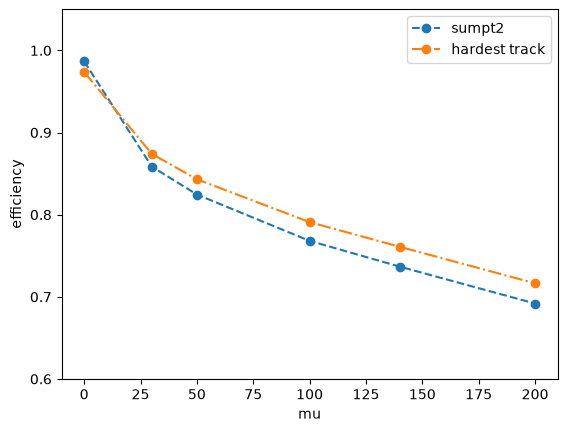

In [133]:
sumpt2_effs = []
eff_conds = []
ceilings = []
htrk_effs = []

for mu in mu_all:
    data = samples.load(mu,slices=samples.SLICES,columns=COLS)
    data_cut = cut(data)
    best_vtx_label = correct_vertex(data_cut)
    htrk_eff = ak.mean(best_vtx_label==0) #arg 0 is trk with highest pt

    # get the vertex with highest sumpt2 
    top = ak.firsts(data_cut.rv_index[ak.argmax(data_cut.rv_sumpt2, axis=1, keepdims=True)])
    sumpt2_eff = ak.mean(ak.fill_none(best_vtx_label == top, False))
    frac_merge = ak.mean(best_vtx_label==-1)
    ceil = 1 - frac_merge

    sumpt2_effs.append(sumpt2_eff)
    ceilings.append(ceil)
    eff_conds.append(sumpt2_eff/ceil)
    htrk_effs.append(htrk_eff)
    print(f'mu = {mu}, sumpt2 efficiency = {sumpt2_eff:.3f}, ceiling = {1-frac_merge:.3f}')

plt.plot(mu_all,sumpt2_effs,linestyle='--',marker='o',label='sumpt2')
plt.plot(mu_all,htrk_effs,linestyle='-.',marker='o',label='hardest track')
plt.ylim(0.6,1.05)
plt.xlabel('mu')
plt.ylabel('efficiency')
plt.legend()

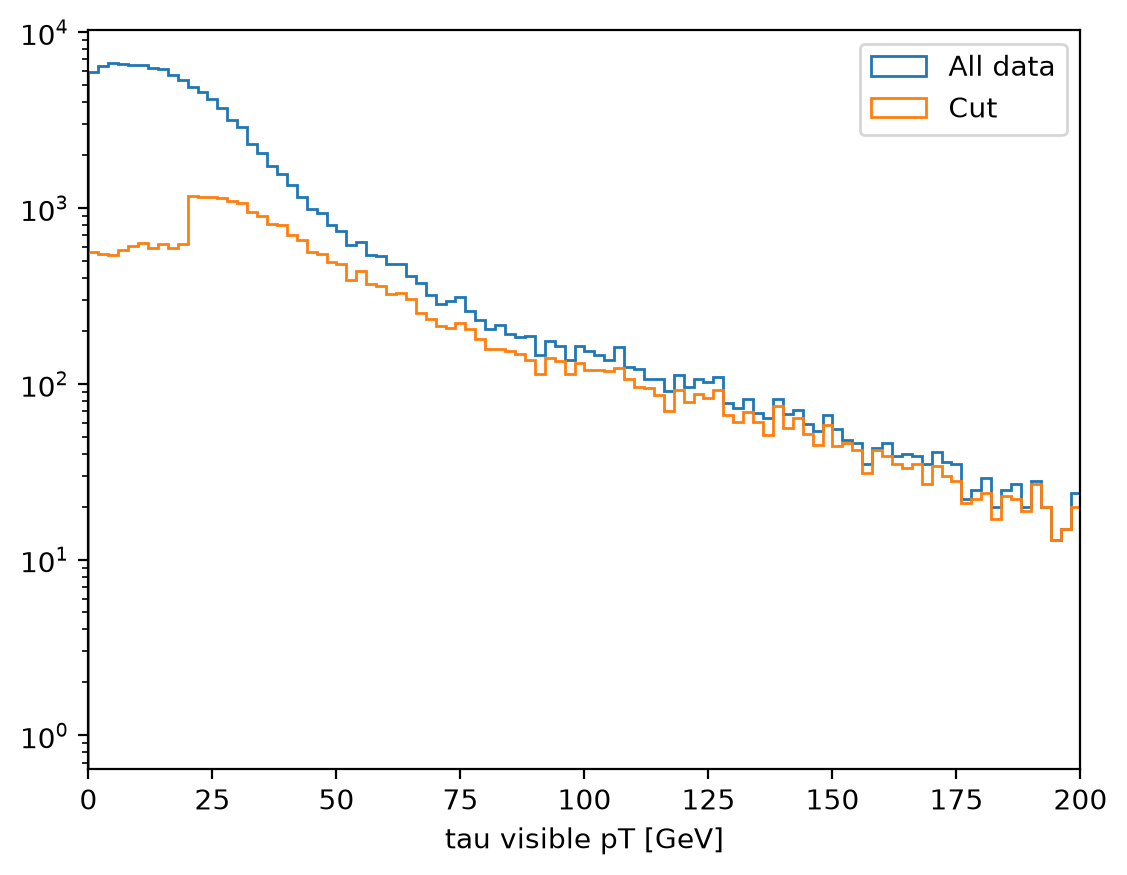

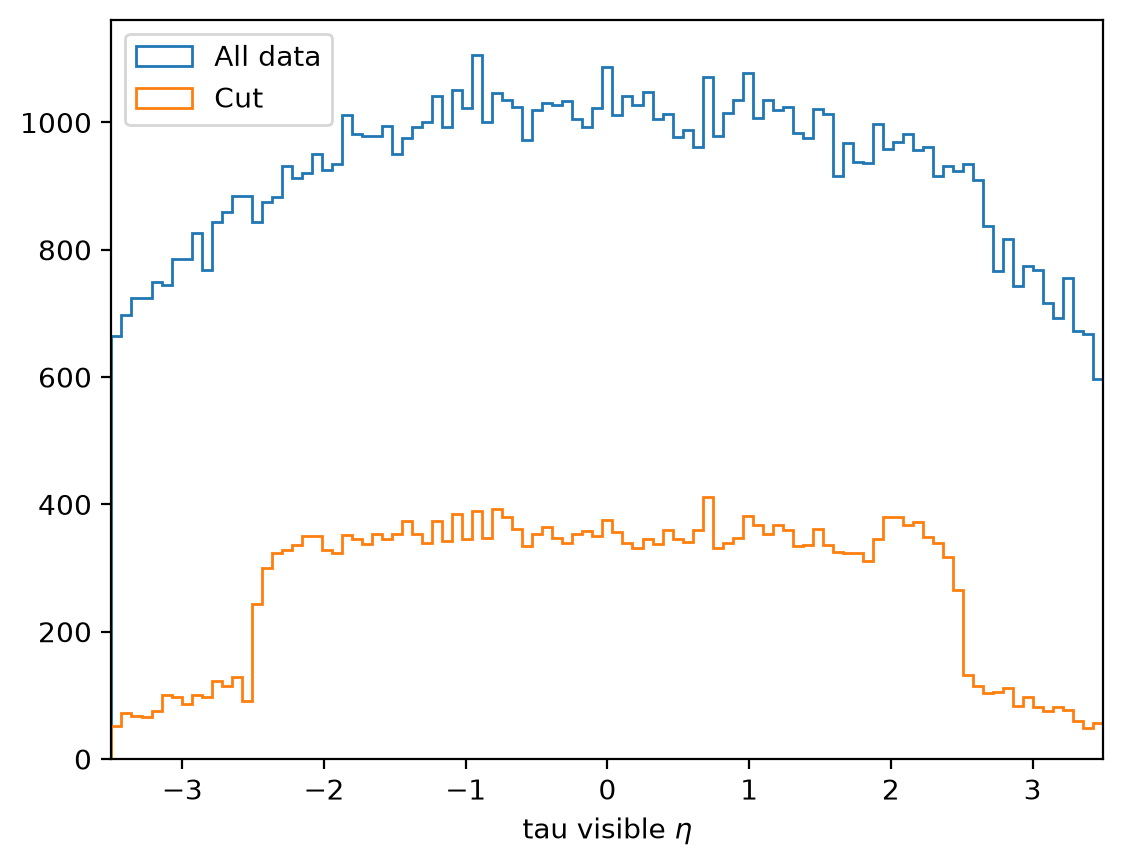

In [134]:
data_cut = cut(data)
bins=np.arange(0,300,2)
plt.figure(dpi=200)
plt.hist(ak.flatten(data.truth_tau_vis_pt),bins=bins,histtype='step',density=False,label='All data')
plt.hist(ak.flatten(data_cut.truth_tau_vis_pt),bins=bins,histtype='step',density=False,label='Cut')
plt.yscale('log')
plt.xlim(0,200)
plt.xlabel('tau visible pT [GeV]')
plt.legend()

bins_eta=np.linspace(-3.5,3.5,100)
plt.figure(dpi=200)
plt.hist(ak.flatten(data.truth_tau_vis_eta),bins=bins_eta,histtype='step',density=False,label='All data')
plt.hist(ak.flatten(data_cut.truth_tau_vis_eta),bins=bins_eta,histtype='step',density=False,label='Cut')
plt.yscale('linear')
plt.xlim(-3.5,3.5)
plt.xlabel(r'tau visible $\eta$')
plt.legend()